# 03 · Task 1 Loan-Amount Regression & Part E Deployable Scoring Service

**Owner:** P3 · Bernard (backed by shared `src/` pipeline)
**Scope:** Exploratory skewness of `Total_Amount` & `duration`, Task 1 regression comparison (`mean`, `ols`, `ridge`, `lasso`, `decision_tree_reg`, `lightgbm_reg`, `lit_linear`) evaluated on both log and original currency scales, residual diagnostics, feature interpretation, and the Part E `score_application()` service with top-3 plain-language reasons and 1,000-call latency benchmarking.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.evaluate import regression_metrics
from src.preprocess import TargetLogScaler, get_feature_lists, load_features, make_preprocessor
from src.score import REQUIRED_APPLICATION_FIELDS, benchmark_latency, score_application
from src.train import build_estimator, fit_and_save_deployment_artifacts, run_cv

## 1. Loan Amount (`Total_Amount`) & Duration Distributions

       amount_local  log_amount_local   duration
count  6.865400e+04         68654.000  68654.000
mean   1.483683e+04             8.575      8.545
std    1.416499e+05             1.264     13.343
min    2.000000e+00             1.099      1.000
25%    2.295000e+03             7.739      7.000
50%    5.249000e+03             8.566      7.000
75%    1.145000e+04             9.346      7.000
max    2.300000e+07            16.951   1096.000


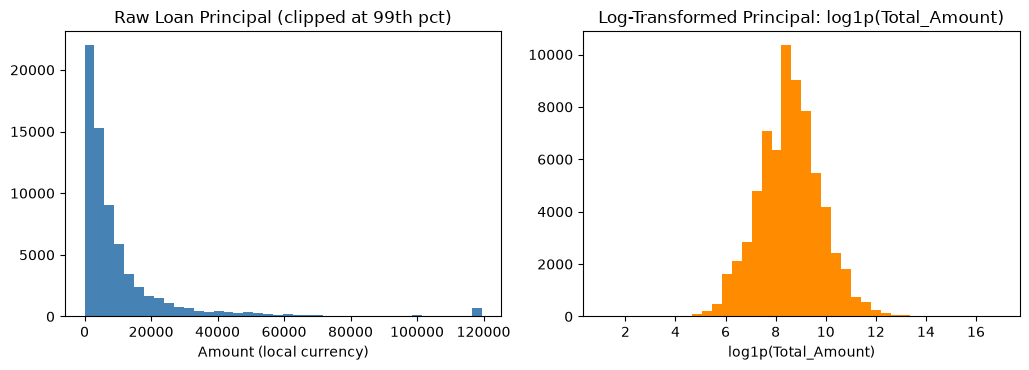

In [2]:
df = load_features()
train_df = df[df["split"] == "train"].copy()
train_df["amount_local"] = np.expm1(train_df["log_amount_local"])

print(train_df[["amount_local", "log_amount_local", "duration"]].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
axes[0].hist(train_df["amount_local"].clip(upper=train_df["amount_local"].quantile(0.99)), bins=40, color="steelblue")
axes[0].set_title("Raw Loan Principal (clipped at 99th pct)")
axes[0].set_xlabel("Amount (local currency)")
axes[1].hist(train_df["log_amount_local"], bins=40, color="darkorange")
axes[1].set_title("Log-Transformed Principal: log1p(Total_Amount)")
axes[1].set_xlabel("log1p(Total_Amount)")
plt.tight_layout()
plt.show()

## 2. Task 1 Model Comparison (`fold_group` & `temporal`)

In [3]:
models_t1 = ["mean", "ols", "ridge", "lasso", "decision_tree_reg", "lightgbm_reg", "lit_linear"]
preds_t1 = {}
reg_rows = []

for m in models_t1:
    p_df = run_cv(df, model_name=m, task="task1", scheme="fold_group", save_preds=True)
    preds_t1[m] = p_df
    met = regression_metrics(p_df["y_true"], p_df["y_pred"])
    reg_rows.append({"model": m, "scheme": "fold_group", **met})

for m in ["mean", "ridge", "lightgbm_reg"]:
    p_df = run_cv(df, model_name=m, task="task1", scheme="temporal", save_preds=True)
    met = regression_metrics(p_df["y_true"], p_df["y_pred"])
    reg_rows.append({"model": m, "scheme": "temporal", **met})

pd.DataFrame(reg_rows).round(4)

Seed set to 42


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


C:\Users\berna\Documents\Ashesi\Machine Learning\Prosit 2\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
C:\Users\berna\Documents\Ashesi\Machine Learning\Prosit 2\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
C:\Users\berna\Documents\Ashesi\Machine Learning\Prosit 2\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Seed set to 42


... (16 outputs left out)

TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


C:\Users\berna\Documents\Ashesi\Machine Learning\Prosit 2\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
C:\Users\berna\Documents\Ashesi\Machine Learning\Prosit 2\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
C:\Users\berna\Documents\Ashesi\Machine Learning\Prosit 2\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


,model,scheme,rmse_orig,mae_orig,rmse_log,mae_log,r2_log,mean_residual_orig
0,mean,fold_group,1.419697e+05,1.231475e+04,1.2637,0.9770,-0.0001,9.538269e+03
1,ols,fold_group,1.753879e+08,6.835149e+05,1.1598,0.9023,0.1575,-6.655863e+05
2,ridge,fold_group,1.402682e+08,7.766143e+05,1.1631,0.9050,0.1528,-7.580981e+05
3,lasso,fold_group,1.400131e+10,7.608589e+07,1.1759,0.9150,0.1340,-7.606663e+07
4,decision_tree_reg,fold_group,1.047824e+05,1.030317e+04,1.1409,0.8799,0.1848,6.037045e+03
5,lightgbm_reg,fold_group,1.236472e+05,1.038818e+04,1.1266,0.8654,0.2051,6.558944e+03
6,lit_linear,fold_group,4.422655e+07,2.511620e+05,1.1671,0.9083,0.1470,-2.324792e+05
7,mean,temporal,2.652864e+05,4.905054e+04,1.6849,1.1085,-0.4059,4.857048e+04
8,ridge,temporal,4.012136e+05,5.302539e+04,1.4543,1.0127,-0.0474,3.746504e+04
9,lightgbm_reg,temporal,2.185586e+05,3.666450e+04,0.9794,0.6111,0.5250,1.997973e+04


**Key diagnostic:** Linear models (`ols`, `ridge`, `lit_linear`) achieve positive `r2_log` (~0.15) on `log1p(Total_Amount)`, but because Kenya's macro indicators barely vary in 2022–2024, outliers extrapolate under `exp()` and inflate original-scale `rmse_orig`. Tree-based models (`decision_tree_reg`, `lightgbm_reg`) naturally bound predictions within observed training leaf ranges and deliver far lower error on both scales.

## 3. Residual Diagnostics & Feature Importance

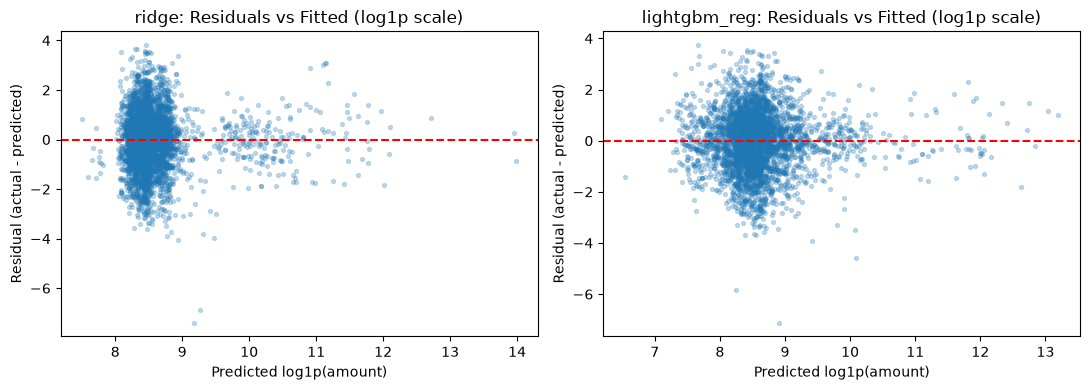

,feature,importance
4,num__n_past_loans,1696
6,num__n_past_labelled,1443
12,num__disb_dom,1159
1,num__Lender_portion_Funded,1123
5,num__days_since_last_loan,1057
10,num__disb_month,877
11,num__disb_dow,554
0,num__duration,327
13,num__macro_inflation,118
25,cat__loan_type_Type_10,79


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m in zip(axes, ["ridge", "lightgbm_reg"]):
    p_df = preds_t1[m]
    yt_log = np.log1p(p_df["y_true"].to_numpy())
    yp_log = np.log1p(np.maximum(0.0, p_df["y_pred"].to_numpy()))
    resid = yt_log - yp_log
    idx = np.random.default_rng(C.SEED).choice(len(resid), size=min(4000, len(resid)), replace=False)
    ax.scatter(yp_log[idx], resid[idx], alpha=0.25, s=8)
    ax.axhline(0.0, color="red", linestyle="--")
    ax.set_title(f"{m}: Residuals vs Fitted (log1p scale)")
    ax.set_xlabel("Predicted log1p(amount)")
    ax.set_ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

# Feature importances from LightGBM regressor fitted on training split
num_t1, cat_t1 = get_feature_lists("task1")
pre = make_preprocessor("task1", sparse_output=False)
X_tr = pre.fit_transform(train_df[num_t1 + cat_t1])
y_tr = TargetLogScaler().fit_transform(train_df["amount_local"].to_numpy())
lgb_reg = build_estimator("lightgbm_reg", task="task1").fit(X_tr, y_tr)
imp = pd.DataFrame({
    "feature": pre.get_feature_names_out(),
    "importance": lgb_reg.feature_importances_,
}).sort_values("importance", ascending=False).head(12)
imp

## 4. Part E Deployable Scoring Service (`src/score.py`) & Latency Benchmark

In [5]:
print("Required application payload specification:")
display(pd.DataFrame([
    {"field": k, "type": v[0], "required": v[2], "description": v[1]}
    for k, v in REQUIRED_APPLICATION_FIELDS.items()
]))

# Save calibrated Task 2 classifier + LightGBM Task 1 limit regressor
paths = fit_and_save_deployment_artifacts(df, clf_model="logreg", reg_model="lightgbm_reg")
print("Saved deployment artifacts:", paths)

kenya_repeat = {
    "customer_id": "KEN_DEMO_101",
    "country_id": "Kenya",
    "lender_id": "267278",
    "loan_type": "Type_1",
    "Total_Amount": 5000.0,
    "duration": 7.0,
    "disbursement_date": "2023-06-12",
    "New_versus_Repeat": "Repeat Loan",
    "n_past_loans": 8,
    "days_since_last_loan": 14.0,
    "n_past_labelled": 7,
    "n_past_defaults": 0,
}
ghana_new = {
    "customer_id": "GHA_DEMO_202",
    "country_id": "Ghana",
    "lender_id": "UNSEEN_GH_LENDER",
    "loan_type": "Type_3",
    "Total_Amount": 350.0,
    "duration": 30.0,
    "disbursement_date": "2023-02-15",
    "New_versus_Repeat": "New Loan",
    "n_past_loans": 0,
}

print("\nKenya Repeat Applicant Decision:", score_application(kenya_repeat))
print("Ghana New Applicant Decision:", score_application(ghana_new))

latency = benchmark_latency(n_calls=1000)
pd.DataFrame([latency]).round(3)

Required application payload specification:


,field,type,required,description
0,customer_id,str,True,Unique borrower identifier
1,country_id,str,True,Operating country ('Kenya' or 'Ghana')
2,lender_id,str,True,Funding lender identifier
3,loan_type,str,True,Loan product type (e.g. 'Type_1')
4,Total_Amount,float,True,Requested loan principal in local currency (> 0)
5,duration,float,True,Requested loan duration in days (> 0)
6,disbursement_date,str,True,Application/disbursement ISO date (YYYY-MM-DD)
7,New_versus_Repeat,str,True,'New Loan' or 'Repeat Loan'
8,Lender_portion_Funded,float,False,"Share funded by lender in [0, 1] (default 0.30)"
9,n_lenders_on_loan,int,False,Number of funding lenders on loan (default 1)


Saved deployment artifacts: {'clf_path': WindowsPath('C:/Users/berna/Documents/Ashesi/Machine Learning/Prosit 2/artifacts/task2_clf.joblib'), 'reg_path': WindowsPath('C:/Users/berna/Documents/Ashesi/Machine Learning/Prosit 2/artifacts/task1_reg.joblib')}



Kenya Repeat Applicant Decision: {'customer_id': 'KEN_DEMO_101', 'probability_of_default': 0.02052, 'threshold': 0.145161, 'decision': 'limit', 'requested_amount': 5000.0, 'recommended_limit': 3695.62, 'top_3_reasons': ['Local currency exchange-rate conditions add risk', 'Limited prior borrowing history on NkwaPay', 'Partner lender channel carries higher historical risk'], 'latency_ms': 309.913}
Ghana New Applicant Decision: {'customer_id': 'GHA_DEMO_202', 'probability_of_default': 0.0, 'threshold': 0.145161, 'decision': 'approve', 'requested_amount': 350.0, 'recommended_limit': 12789.04, 'top_3_reasons': ['Exchange-rate environment supports repayment stability', 'Prevailing interest-rate environment supports repayment', 'Macroeconomic inflation environment is relatively stable'], 'latency_ms': 61.531}


,n_calls,median_ms,p95_ms,mean_ms,min_ms,max_ms
0,1000.0,66.894,89.705,66.997,23.479,142.117
